# Model selection

In [1]:
import numpy as np
import scipy
import pymc as pm
import arviz as az

In [2]:
print(f"Running on PyMC version {pm.__version__} and ArviZ version {az.__version__}")

Running on PyMC version 5.28.5 and ArviZ version 0.23.4


In [3]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,6)

Your aim in this assignment is to find the model that best fits the data

In [4]:
data= np.loadtxt('data.txt')

The data is from an discrete distribution. You can use the function below to plot the histogram.

In [5]:
def plot_discrete_hist(data, ax = None, **kwargs):
    if ax is None:
        ax =plt.gca()
    min, max = data.min(), data.max()
    n_bins=int(max-min+1)
    return ax.hist(data, bins=n_bins, range=(min-0.5, max+0.5), **kwargs)

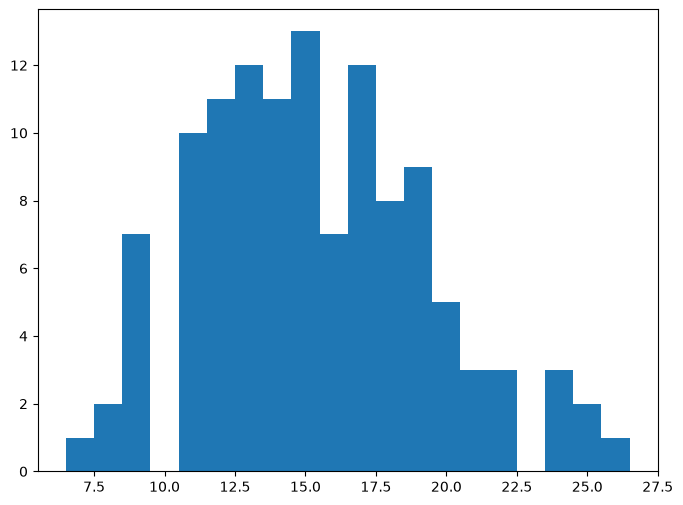

In [6]:
fig, ax = plt.subplots()
plot_discrete_hist(data, ax=ax);

### Problem 1

Check if the data can be explained by the binomial distribution with $n=35$. Make a posterior predictive check.

In [7]:
tune = 1000
draws = 8000

In [8]:
with pm.Model() as binom_35:
    p   = pm.Beta("p", alpha=1, beta=1)
    obs = pm.Binomial("obs", n=35, p=p, observed=data)

    traceb35 = pm.sample(
        tune = 1000,
        draws = 8000,
        chains=4,
        target_accept=0.9,
        random_seed=42,
        return_inferencedata=True,
        idata_kwargs={"log_likelihood": True},
    )
    ppcb35 = pm.sample_posterior_predictive(
        traceb35,
        var_names=["obs"],
        extend_inferencedata=True,   
        random_seed=42,
    )

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [p]


Sampling 4 chains for 1_000 tune and 8_000 draw iterations (4_000 + 32_000 draws total) took 11 seconds.


Sampling: [obs]


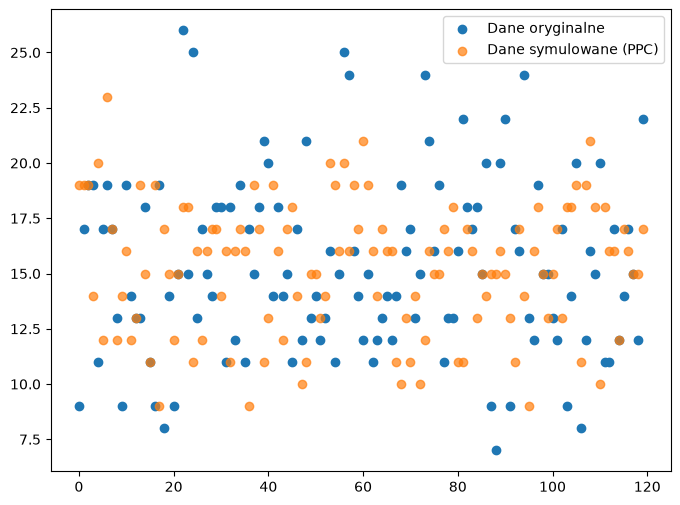

In [9]:
x = np.arange(len(data))                      
pp_samples = ppcb35.posterior_predictive.obs.values.ravel()

y_sim = pp_samples[: len(data)]
plt.scatter(x, data,     label="Dane oryginalne")
plt.scatter(x, y_sim,    label="Dane symulowane (PPC)", alpha=0.7)
plt.legend()
plt.show()

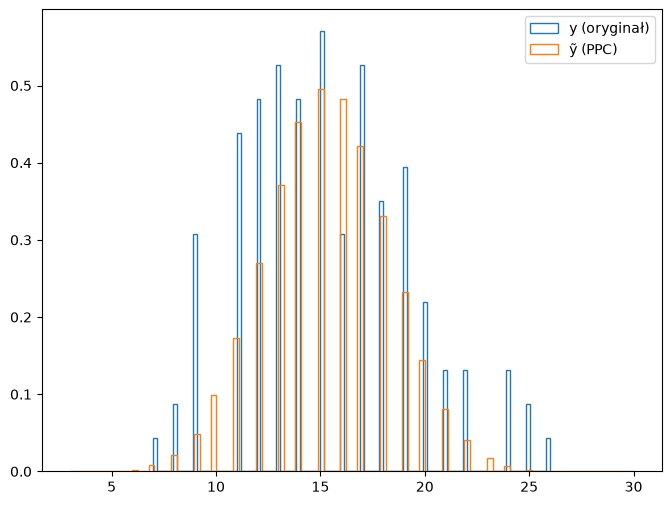

In [10]:
pp_samples = ppcb35.posterior_predictive.obs.values.ravel()
plt.hist(data,        bins=100, histtype="step", density=True, label="y (oryginał)")
plt.hist(pp_samples,  bins=100, histtype="step", density=True, label="ỹ (PPC)")

plt.legend()
plt.show()

In [11]:
#Nasza data i data syntetyczna wyglądają dojść podobnie, ale sprawdzimy jeszcze możliwości zyskania minimów maksimów i std 

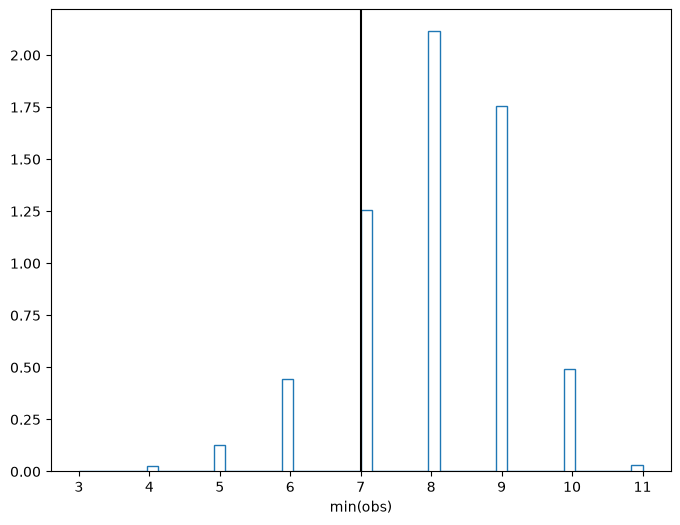

In [12]:
#Min
pps35 = traceb35.posterior_predictive["obs"].stack(z=("chain", "draw")).transpose()

plt.hist(np.min(pps35, axis=1), histtype="step", density=True, bins=50)
plt.xlabel("min(obs)")
plt.axvline(data.min(), color="black")      
plt.show()

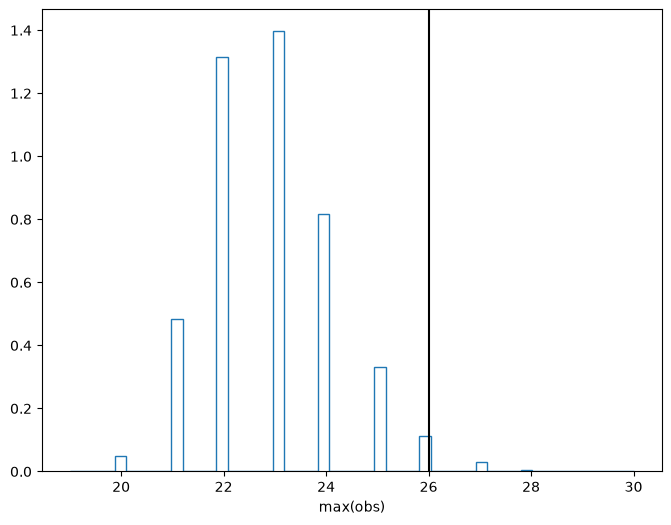

In [13]:
#Max
plt.hist(np.max(pps35, axis=1), histtype='step', density=True, bins=50);
plt.xlabel("max(obs)")
plt.axvline(data.max(), color='black');

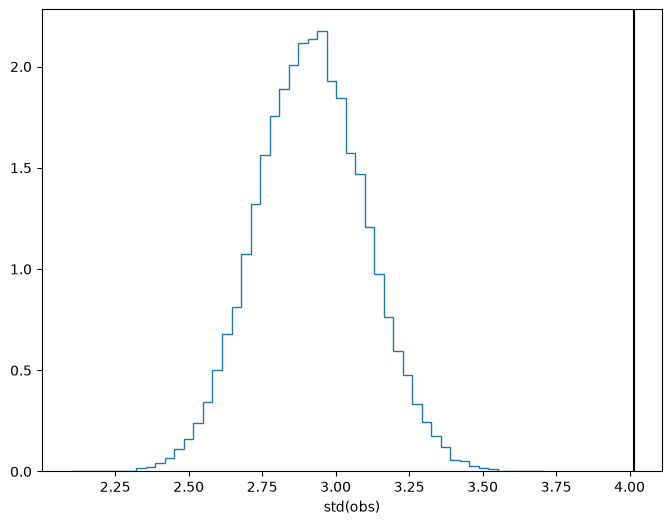

In [14]:
plt.hist(np.std(pps35, axis=1), histtype='step', density=True, bins=50);
plt.xlabel("std(obs)")
plt.axvline(data.std(), color='black');

In [15]:
#Z danych syntetycznych można zyskać maksimum, minimum ale nie można zyskać std

### Problem 2

Repeat the same for binomial distribution with $n=45$.

In [16]:
with pm.Model() as binom_45:
    # prior
    p = pm.Beta("p", alpha=1, beta=1)

    # likelihood
    obs = pm.Binomial("obs", n=45, p=p, observed=data)

    # posterior
    traceb45 = pm.sample(
    return_inferencedata=True,
    idata_kwargs={"log_likelihood": True},  
    random_seed=42,
    target_accept=0.9
    )


    # posterior predictive
    ppcb45 = pm.sample_posterior_predictive(
        traceb45,
        var_names=["obs"],
        extend_inferencedata=True,
        random_seed=42,
    )

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [p]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 9 seconds.


Sampling: [obs]


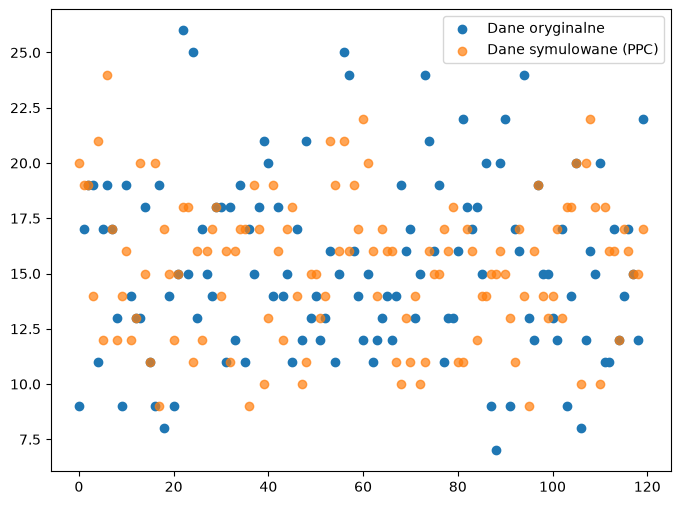

In [17]:
x = np.arange(len(data))                      
pp_samples = ppcb45.posterior_predictive.obs.values.ravel()

y_sim = pp_samples[: len(data)]
plt.scatter(x, data,     label="Dane oryginalne")
plt.scatter(x, y_sim,    label="Dane symulowane (PPC)", alpha=0.7)
plt.legend()
plt.show()

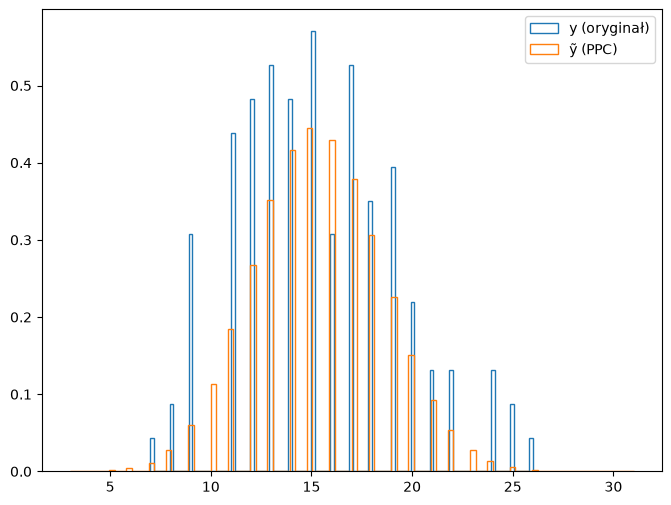

In [18]:
pp_samples45 = ppcb45.posterior_predictive.obs.values.ravel()
plt.hist(data,        bins=100, histtype="step", density=True, label="y (oryginał)")
plt.hist(pp_samples45,  bins=100, histtype="step", density=True, label="ỹ (PPC)")

plt.legend()
plt.show()

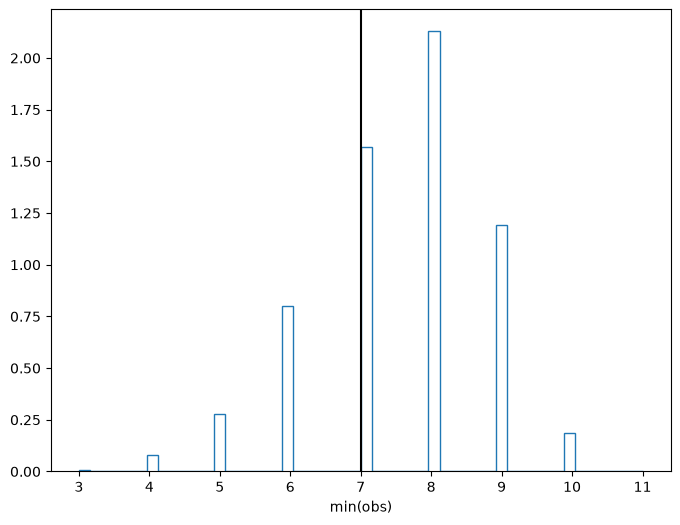

In [19]:
pps45 = traceb45.posterior_predictive["obs"].stack(z=("chain", "draw")).transpose()

plt.hist(np.min(pps45, axis=1), histtype="step", density=True, bins=50)
plt.xlabel("min(obs)")
plt.axvline(data.min(), color="black")      
plt.show()

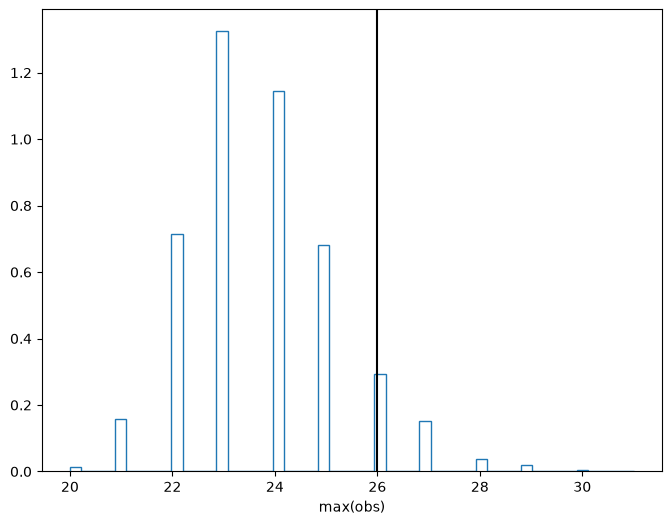

In [20]:
plt.hist(np.max(pps45, axis=1), histtype='step', density=True, bins=50);
plt.xlabel("max(obs)")
plt.axvline(data.max(), color='black');

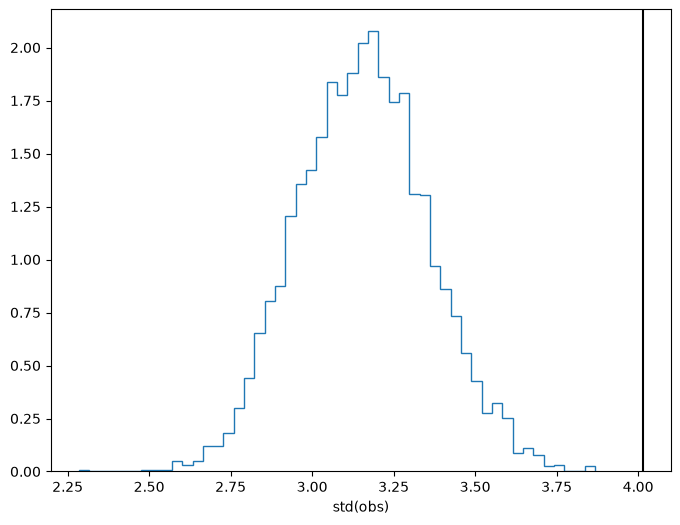

In [21]:
plt.hist(np.std(pps45, axis=1), histtype='step', density=True, bins=50);
plt.xlabel("std(obs)")
plt.axvline(data.std(), color='black');

In [22]:
#Z danych syntetycznych można zyskać maksimum, minimum ale nie można zyskać std

### Problem 3

Repeat the same for poisson distribution.

$$p(k)=e^{-\lambda}\frac{\lambda^k}{k!}$$

 Use $\Gamma$ distribution for prior on the $\lambda$ parameter of the distribution.

In [23]:
with pm.Model() as model_pois:
    lam = pm.Gamma("lam", alpha=1.0, beta=1.0)   
    obs = pm.Poisson("obs", mu=lam, observed=data)

    trace_pois = pm.sample(
        tune=tune,
        draws=draws,
        chains=4,
        target_accept=0.9,
        random_seed=42,
        return_inferencedata=True,
        idata_kwargs={"log_likelihood": True},
    )

    ppc_pois = pm.sample_posterior_predictive(
        trace_pois,
        var_names=["obs"],
        extend_inferencedata=True,
        random_seed=42,
    )

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [lam]


Sampling 4 chains for 1_000 tune and 8_000 draw iterations (4_000 + 32_000 draws total) took 11 seconds.


Sampling: [obs]


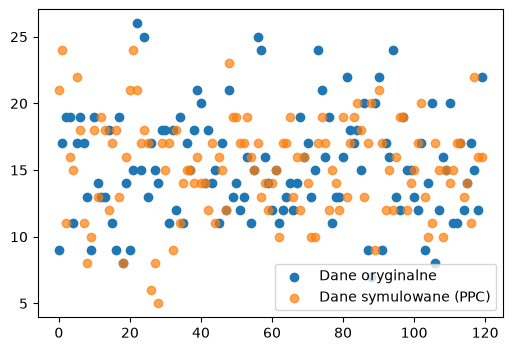

In [24]:
x = np.arange(len(data))
pp_samples = ppc_pois.posterior_predictive.obs.values.ravel()
y_sim = pp_samples[: len(data)]          

plt.figure(figsize=(6, 4))
plt.scatter(x, data,  label="Dane oryginalne")
plt.scatter(x, y_sim, label="Dane symulowane (PPC)", alpha=0.7)
plt.legend()
plt.show()

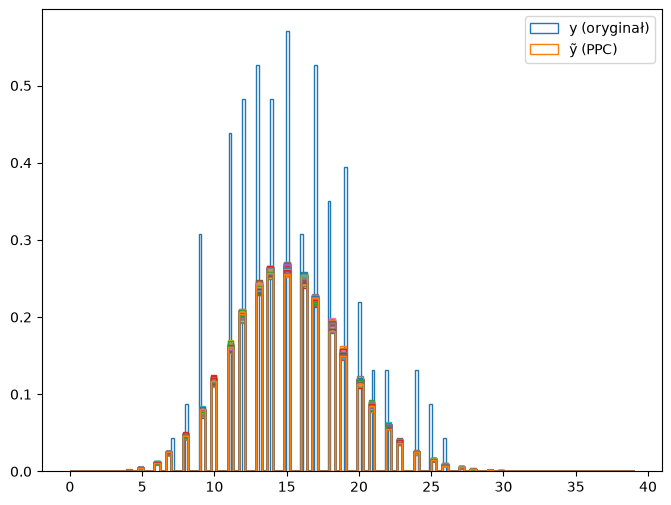

In [25]:
pps = ppc_pois.posterior_predictive["obs"].stack(z=("chain", "draw")).transpose()
plt.hist(data,        bins=100, histtype="step", density=True, label="y (oryginał)")
plt.hist(pps,  bins=100, histtype="step", density=True, label="ỹ (PPC)")

plt.legend()
plt.show()

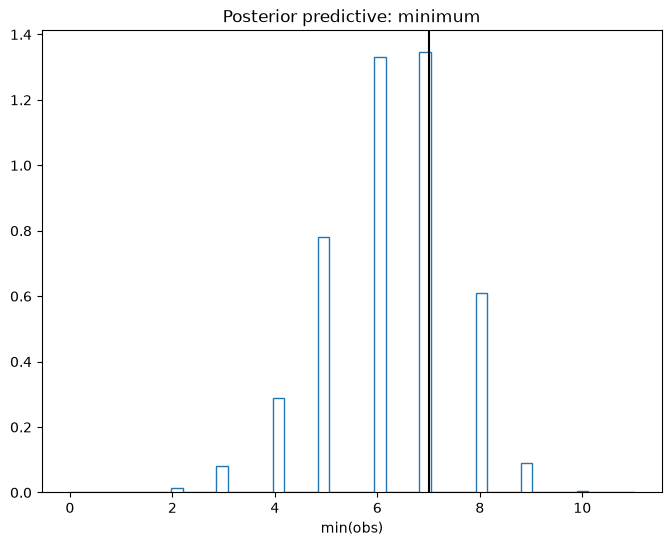

In [26]:
plt.hist(np.min(pps, axis=1), histtype="step", density=True, bins=50)
plt.axvline(data.min(), color="black")
plt.xlabel("min(obs)")
plt.title("Posterior predictive: minimum")
plt.show()

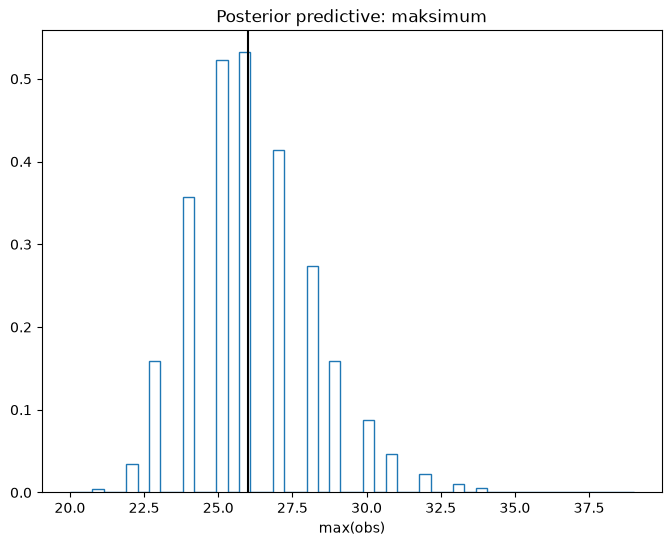

In [27]:
plt.hist(np.max(pps, axis=1), histtype="step", density=True, bins=50)
plt.axvline(data.max(), color="black")
plt.xlabel("max(obs)")
plt.title("Posterior predictive: maksimum")
plt.show()

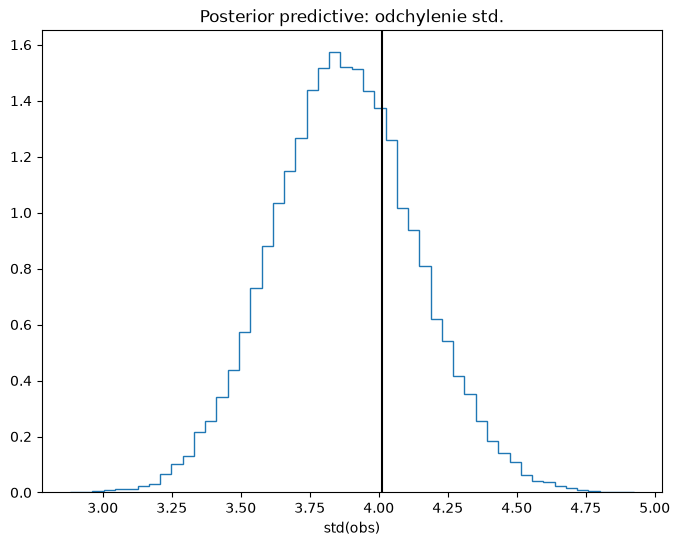

In [28]:
plt.hist(np.std(pps, axis=1), histtype="step", density=True, bins=50)
plt.axvline(data.std(), color="black")
plt.xlabel("std(obs)")
plt.title("Posterior predictive: odchylenie std.")
plt.show()

In [29]:
#Z danych syntetycznych można zyskać maksimum, minimum i już można zyskać std, więc ten model jest najlepszy.

### Problem 4

Compare the three models using the "leave one out" cross validation.

If you can, explain the results :)

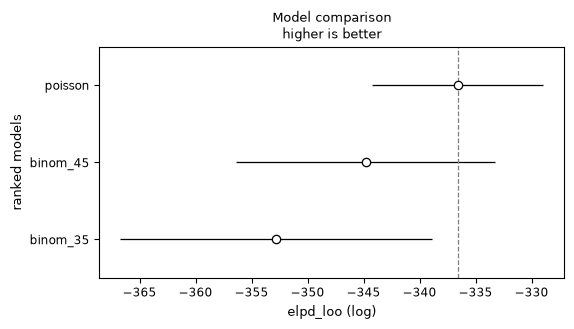

In [30]:
comp_df = az.compare({
    "binom_35": traceb35,
    "binom_45": traceb45,
    "poisson": ppc_pois
})
az.plot_compare(comp_df);